In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa constructora ha resultado adjudicataria de una obra pública. El pliego incluye, como **condición especial de ejecución** de carácter social calificada de **obligación contractual esencial**, que **al menos el 20 % de las operario-semanas** de la obra las realicen personas en situación de desempleo de larga duración contratadas para la obra a través del servicio público de empleo, con una penalidad de 5 k€ por cada punto porcentual no alcanzado y resolución del contrato si no se alcanza la mitad. El cuadro de prelaciones, las duraciones (semanas), los operarios de cada actividad y si la actividad admite personal de inserción sin cualificación específica (`apta` = 1: peonaje, desbroce, acopios, limpieza, ayudas) se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources, apta
    ('A'     , '---'      , 2       , 1        , 0   ),
    ('B'     , '---'      , 2       , 4        , 1   ),
    ('C'     , 'A,B'      , 2       , 3        , 1   ),
    ('D'     , 'A'        , 4       , 4        , 1   ),
    ('E'     , 'D'        , 4       , 4        , 0   ),
    ('F'     , 'B,E'      , 7       , 2        , 0   ),
    ('G'     , 'C'        , 4       , 1        , 1   ),
    ('H'     , 'E,G'      , 3       , 4        , 0   ),
], columns=['activity', 'predecessor', 'duration', 'resources', 'apta']).set_index('activity')
datos_enunciado

,predecessor,duration,resources,apta
activity,,,,
A,---,2,1,0
B,---,2,4,1
C,"A,B",2,3,1
D,A,4,4,1
E,D,4,4,0
F,"B,E",7,2,0
G,C,4,1,1
H,"E,G",3,4,0


El servicio de empleo y el plan de formación permiten incorporar como máximo **2 persona(s) de inserción por semana** (cada una necesita un tutor en la cuadrilla); cada operario-semana de inserción cuesta 0.3 k€ más que uno ordinario (tutoría, formación y rendimiento inicial).

> **De: Director de producción**
> Eso se cubre en el papel: la subcontrata de pintura dice que su gente es de inserción y listo, o contamos a los peones de siempre, que alguno estuvo en paro. Y si no, se lo pasamos a la subcontrata en su contrato, que para eso está. No voy a parar la obra por una cláusula social.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S14 — Condiciones especiales de ejecución del contrato.** Una condición especial de ejecución de tipo social o ambiental fijada en el pliego es una obligación del contrato, no una recomendación: se planifica como el alcance, se verifica con documentación y su incumplimiento lleva penalidad o, si el pliego la califica de esencial, resolución. Se exige igualmente a los subcontratistas, de modo que trasladar la obligación a la cadena no la cumple ni la elimina. Si el plan la cumple o no es un cálculo (operarios-semana, kWh, toneladas) con los datos del enunciado. *(cf. LCSP (Ley 9/2017), art. 202.1 a 202.4; ICB4, Perspectiva 3 «cumplimiento, estándares y regulaciones».)*
- **S10 — Condiciones de trabajo en la cadena de ejecución.** El plan no puede apoyarse en condiciones de trabajo que la norma prohíbe: ni en una cadena de subcontratación más larga que la permitida, ni en jornadas al aire libre que ignoren los avisos por calor extremo. Una ventaja de coste o plazo obtenida así no es una opción de la tabla (cf. C7 y C5 de la lección 19). *(cf. Ley 32/2006 de subcontratación en la construcción, arts. 4 y 5; RD 486/1997, disposición adicional única (RDL 4/2023); ICB4, Perspectiva 3 «salud, seguridad y medio ambiente».)*
- **Norma o dato de referencia — el pliego debe incluir al menos una condición especial de ejecución de tipo medioambiental, social o relativa a la innovación (por ejemplo, combatir el paro, en particular el juvenil o el de larga duración, o la igualdad en el empleo); los pliegos pueden fijar penalidades por su incumplimiento o calificarlas de obligaciones contractuales esenciales a efectos de resolución, y todas se exigen igualmente a los subcontratistas que participen en la ejecución** *(Ley 9/2017 (LCSP), art. 202.1, 202.2, 202.3 y 202.4.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Con el diagrama de cargas de inicios más tempranos, calcule las operario-semanas totales de la obra, las que exige la cláusula (20 %) y la capacidad máxima de operario-semanas de inserción (semana a semana, el mínimo entre 2 y la carga de las actividades aptas). ¿Cumple el plan? Nivele las cargas dentro de las holguras y repita el cálculo.  "
pregunta_2 = "2. (A) Calcule el coste de cumplir la cláusula (operario-semanas de inserción por su sobrecoste) y el coste de no cumplirla con el plan de inicios más tempranos (puntos de déficit por la penalidad). ¿Cuánto cuesta la cláusula frente a la penalidad?  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿es la condición una obligación o una recomendación? ¿La cumple el plan con inicios más tempranos? ¿Y tras nivelar? ¿Vale trasladarla a la subcontrata o «cubrirla en el papel»?  "
pregunta_4 = "4. (C) ¿Qué propone al director de producción y qué comunica al responsable del contrato? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Con el diagrama de cargas de inicios más tempranos, calcule las operario-semanas totales de la obra, las que exige la cláusula (20 %) y la capacidad máxima de operario-semanas de inserción (semana a semana, el mínimo entre 2 y la carga de las actividades aptas). ¿Cumple el plan? Nivele las cargas dentro de las holguras y repita el cálculo.  

2. (A) Calcule el coste de cumplir la cláusula (operario-semanas de inserción por su sobrecoste) y el coste de no cumplirla con el plan de inicios más tempranos (puntos de déficit por la penalidad). ¿Cuánto cuesta la cláusula frente a la penalidad?  

3. (B) Según el criterio y la norma de referencia, ¿es la condición una obligación o una recomendación? ¿La cumple el plan con inicios más tempranos? ¿Y tras nivelar? ¿Vale trasladarla a la subcontrata o «cubrirla en el papel»?  

4. (C) ¿Qué propone al director de producción y qué comunica al responsable del contrato? Aplique la rúbrica.  

# Resolución

In [6]:
porcentaje, maximo_insercion, coste_tutoria, penalidad_punto = 20, 2, 0.3, 5
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
aptas = sorted(datos_proyecto.index[datos_proyecto['apta'] == 1])
def carga_por_semana(gantt_df, filas):
    '''Carga semanal de las filas indicadas de un Gantt de cargas (celdas vacías = 0).'''
    cols = [c for c in gantt_df.data.columns if c != 'H_total']
    filas = [f for f in filas if f in gantt_df.data.index]
    return gantt_df.data.loc[filas, cols].apply(pd.to_numeric, errors='coerce').fillna(0).sum()

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = \max\{0+2,\ 0+2\} = 2$ &nbsp; (A, B)
- $T_{D} = 0+2 = 2$ &nbsp; (A)
- $T_{E} = 2+4 = 6$ &nbsp; (D)
- $T_{G} = 2+2 = 4$ &nbsp; (C)
- $T_{F} = \max\{0+2,\ 6+4\} = 10$ &nbsp; (B, E)
- $T_{H} = \max\{6+4,\ 4+4\} = 10$ &nbsp; (E, G)
- $T_{\mathrm{Fin}} = \max\{10+7,\ 10+3\} = 17$ &nbsp; (F, H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 17$
- $T_{H}^{*} = 17-3 = 14$ &nbsp; (Fin)
- $T_{F}^{*} = 17-7 = 10$ &nbsp; (Fin)
- $T_{G}^{*} = 14-4 = 10$ &nbsp; (H)
- $T_{E}^{*} = \min\{10-4,\ 14-4\} = 6$ &nbsp; (F, H)
- $T_{D}^{*} = 6-4 = 2$ &nbsp; (E)
- $T_{C}^{*} = 10-2 = 8$ &nbsp; (G)
- $T_{B}^{*} = \min\{8-2,\ 10-2\} = 6$ &nbsp; (C, F)
- $T_{A}^{*} = \min\{8-2,\ 2-2\} = 0$ &nbsp; (C, D)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 6-0\} = 0$ &nbsp; (A, B)

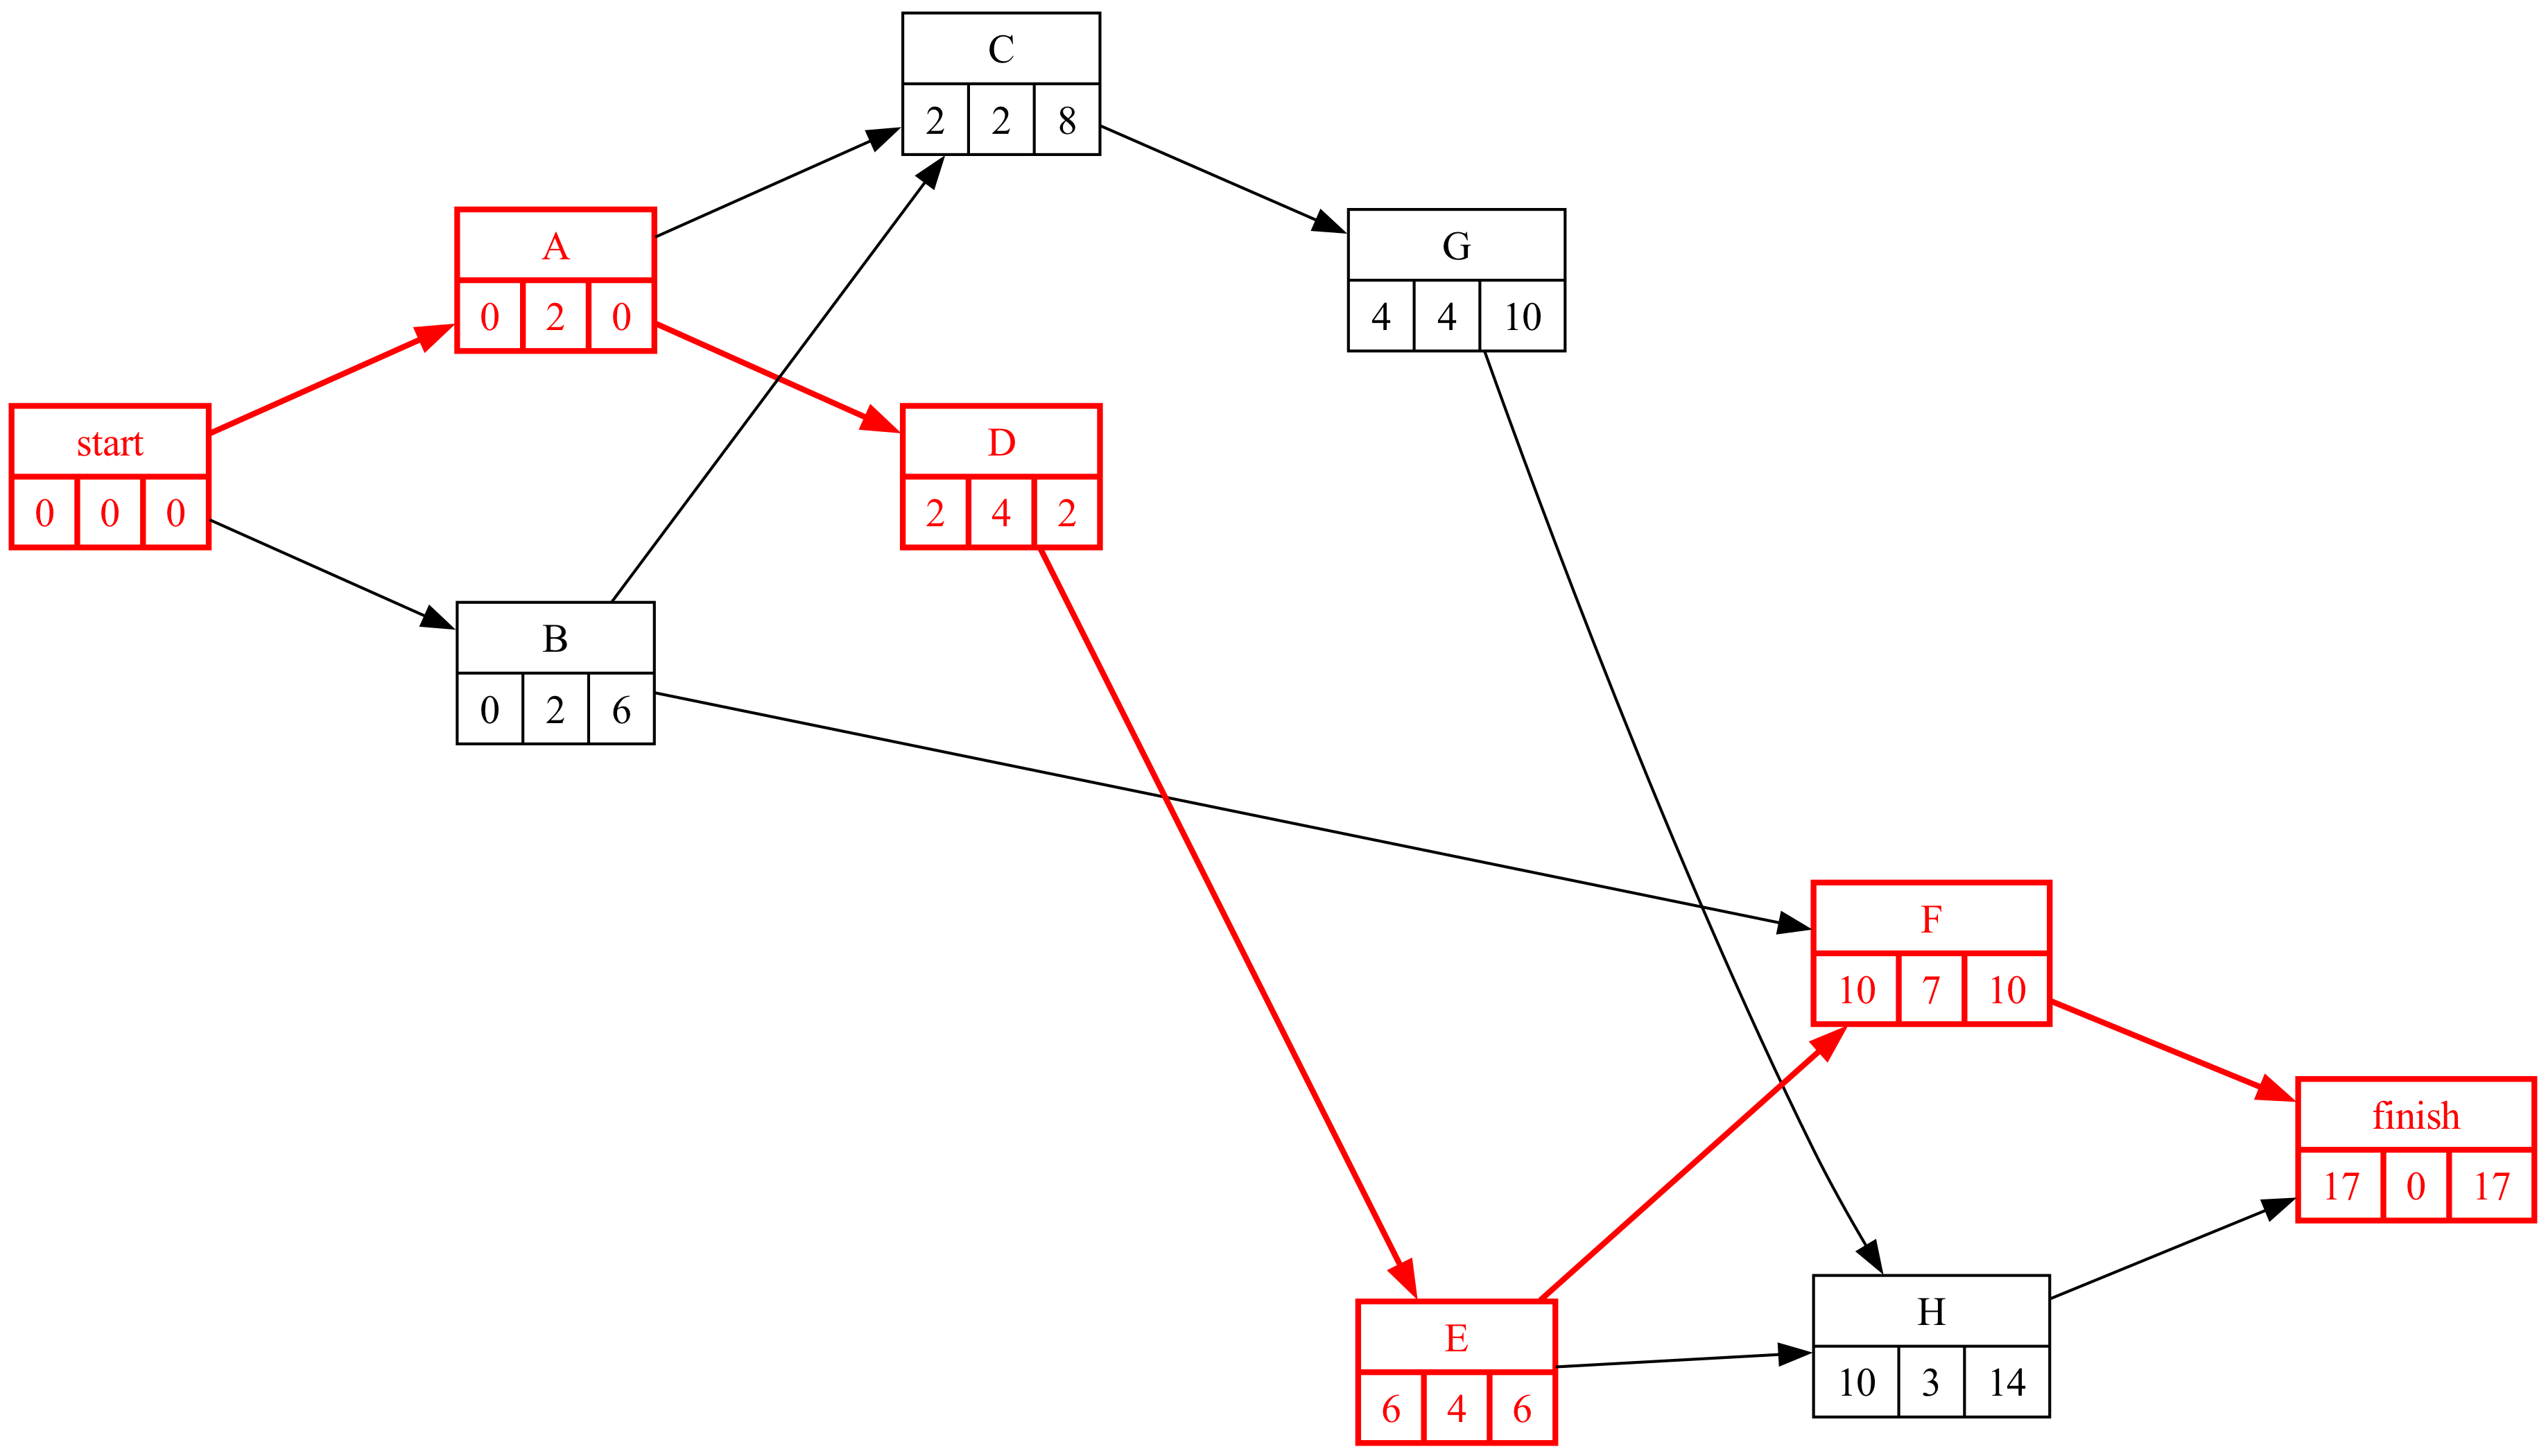

In [8]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Con el diagrama de cargas de inicios más tempranos, calcule las operario-semanas totales de la obra, las que exige la cláusula (20 %) y la capacidad máxima de operario-semanas de inserción (semana a semana, el mínimo entre 2 y la carga de las actividades aptas). ¿Cumple el plan? Nivele las cargas dentro de las holguras y repita el cálculo.  

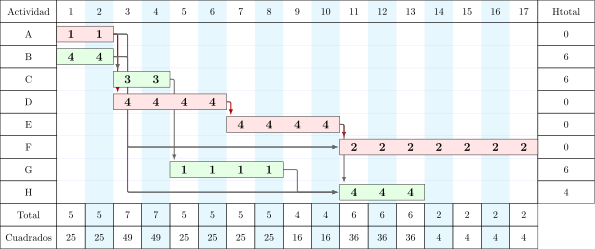

In [10]:
#| fig-cap: "Gantt con inicios más tempranos y carga de operarios"
#| label: fig-ganttCargas
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

In [11]:
#| tbl-cap: "Carga total, carga de las actividades aptas y capacidad de inserción, semana a semana (inicios más tempranos)"
#| label: tbl-capacidad
carga_total = carga_por_semana(gantt_inicial, list(datos_proyecto.index))
carga_aptas = carga_por_semana(gantt_inicial, aptas)
capacidad = carga_aptas.clip(upper=maximo_insercion)
tabla = pd.DataFrame({'carga total': carga_total, 'carga de las aptas': carga_aptas, f'inserción posible (mín con {maximo_insercion})': capacidad})
tabla.loc['Total'] = tabla.sum()
display(tabla.astype(int).T)
total = float(carga_total.sum()); requerido = int(np.ceil(porcentaje / 100 * total)); capacidad_inicial = float(capacidad.sum())
Markdown(f'''Operario-semanas de la obra: **{total:.0f}**; la cláusula exige al menos {porcentaje} %: **{requerido}**. Con inicios más tempranos, las actividades aptas admiten como máximo **{capacidad_inicial:.0f}** operario-semanas de inserción ({capacidad_inicial / total:.1%}): ''' + ('**cumple**.' if capacidad_inicial >= requerido else '**no cumple**: las actividades aptas se solapan y el límite semanal desperdicia su carga.'))

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,Total
carga total,5,5,7,7,5,5,5,5,4,4,6,6,6,2,2,2,2,78
carga de las aptas,4,4,7,7,5,5,1,1,0,0,0,0,0,0,0,0,0,34
inserción posible (mín con 2),2,2,2,2,2,2,1,1,0,0,0,0,0,0,0,0,0,14


Operario-semanas de la obra: **78**; la cláusula exige al menos 20 %: **16**. Con inicios más tempranos, las actividades aptas admiten como máximo **14** operario-semanas de inserción (17.9%): **no cumple**: las actividades aptas se solapan y el límite semanal desperdicia su carga.

In [12]:
#| tbl-cap: "Desplazamientos de la nivelación y capacidad de inserción tras nivelar"
#| label: tbl-nivelacion
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo_niv = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources')
display(desplazamientos[desplazamientos['desplazamientos'] > 0])
carga_aptas_niv = carga_por_semana(gantt_nivelado, aptas)
capacidad_niv = carga_aptas_niv.clip(upper=maximo_insercion)
tabla_niv = pd.DataFrame({'carga de las aptas (nivelada)': carga_aptas_niv, f'inserción posible (mín con {maximo_insercion})': capacidad_niv})
tabla_niv.loc['Total'] = tabla_niv.sum()
display(tabla_niv.astype(int).T)
capacidad_nivelada = float(capacidad_niv.sum())
Markdown(f'''Tras nivelar (misma duración, {duracion} semanas) la capacidad de inserción es **{capacidad_nivelada:.0f}** operario-semanas ({capacidad_nivelada / total:.1%}): ''' + ('**cumple** la cláusula.' if capacidad_nivelada >= requerido else 'sigue sin cumplir.'))

,desplazamientos
C,6


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,Total
carga de las aptas (nivelada),4,4,4,4,4,4,0,0,3,3,1,1,1,1,0,0,0,34
inserción posible (mín con 2),2,2,2,2,2,2,0,0,2,2,1,1,1,1,0,0,0,20


Tras nivelar (misma duración, 17 semanas) la capacidad de inserción es **20** operario-semanas (25.6%): **cumple** la cláusula.

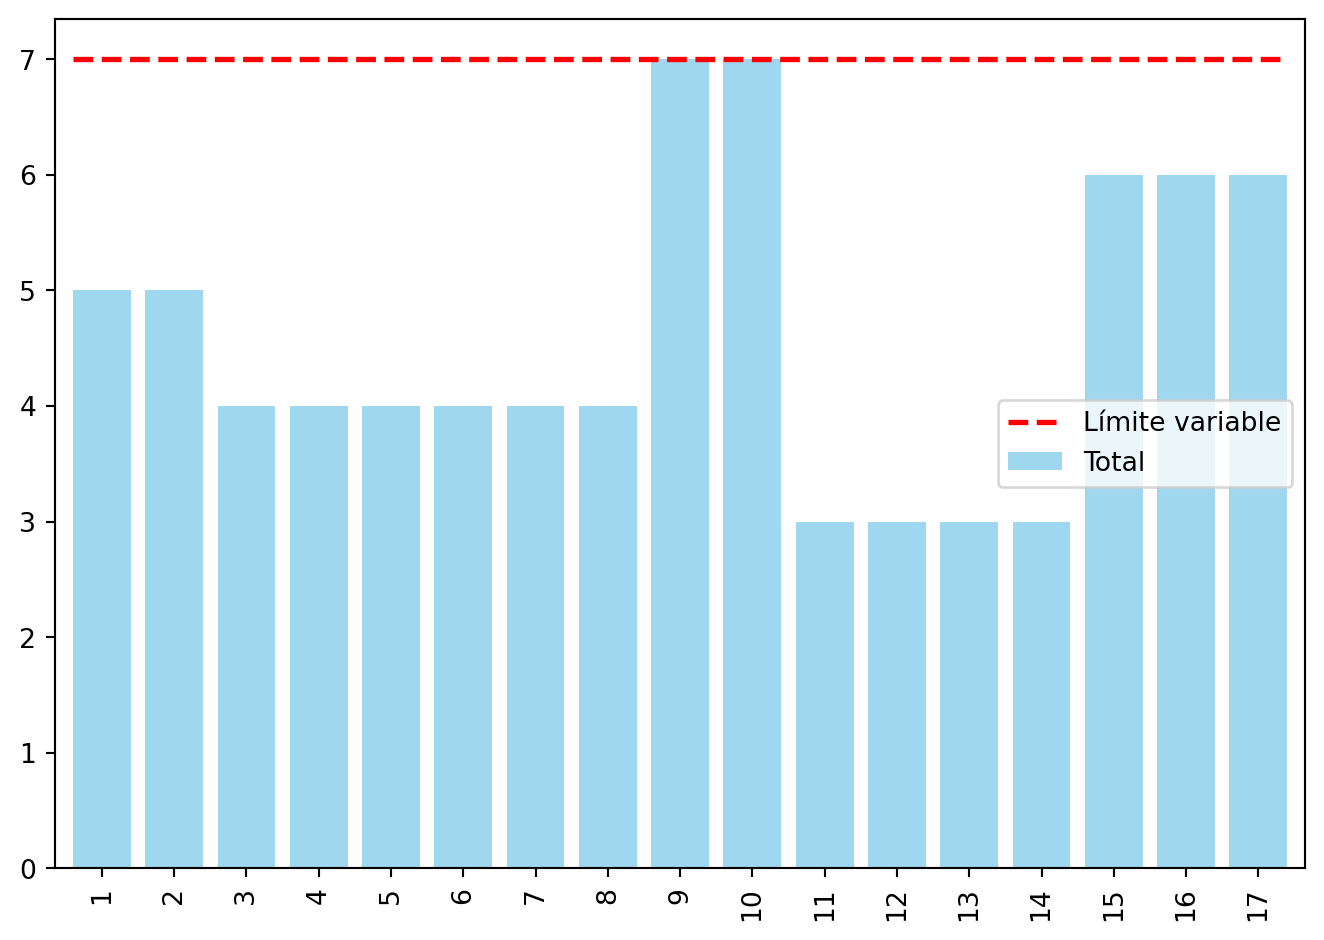

In [13]:
#| fig-cap: "Diagrama de cargas tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=[int(carga_total.max())])

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste de cumplir la cláusula (operario-semanas de inserción por su sobrecoste) y el coste de no cumplirla con el plan de inicios más tempranos (puntos de déficit por la penalidad). ¿Cuánto cuesta la cláusula frente a la penalidad?  

In [15]:
#| tbl-cap: "Coste de cumplir frente a coste de no cumplir"
#| label: tbl-coste
deficit_inicial = max(0, requerido - capacidad_inicial)
puntos_deficit = 100 * deficit_inicial / total
costes = pd.Series({'cumplir tras nivelar: sobrecoste de tutoría (k€)': requerido * coste_tutoria,
                    'plan inicial sin nivelar: déficit (operario-semanas)': deficit_inicial,
                    'plan inicial sin nivelar: déficit (puntos porcentuales)': puntos_deficit,
                    'plan inicial sin nivelar: penalidad (k€)': puntos_deficit * penalidad_punto})
display(costes.round(2).to_frame('valor'))
Markdown(f'''Cumplir cuesta **{requerido * coste_tutoria:.1f} k€** de tutoría y una nivelación que no alarga la obra; no cumplir con el plan inicial deja {deficit_inicial:.0f} operario-semanas de déficit ({puntos_deficit:.1f} puntos), **{puntos_deficit * penalidad_punto:.1f} k€** de penalidad''' + (' y, por debajo de la mitad, causa de resolución.' if capacidad_inicial < requerido / 2 else '.'))

,valor
cumplir tras nivelar: sobrecoste de tutoría (k€),4.80
plan inicial sin nivelar: déficit (operario-semanas),2.00
plan inicial sin nivelar: déficit (puntos porcentuales),2.56
plan inicial sin nivelar: penalidad (k€),12.82


Cumplir cuesta **4.8 k€** de tutoría y una nivelación que no alarga la obra; no cumplir con el plan inicial deja 2 operario-semanas de déficit (2.6 puntos), **12.8 k€** de penalidad.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿es la condición una obligación o una recomendación? ¿La cumple el plan con inicios más tempranos? ¿Y tras nivelar? ¿Vale trasladarla a la subcontrata o «cubrirla en el papel»?  

**Norma y S14.** La condición especial de ejecución es una **obligación del contrato** (LCSP, art. 202): el pliego la ha calificado de esencial, de modo que su incumplimiento lleva la penalidad y, por debajo de la mitad, la resolución (art. 202.3). Se exige igualmente a los subcontratistas (art. 202.4): pasarla a la subcontrata **no la traslada**, la extiende; y «cubrirla en el papel» con personal que no cumple la definición del pliego es una afirmación falsa en la certificación (lección 19, C1), además de incumplir. Si el plan la cumple es un cálculo: con inicios más tempranos la capacidad es de 14 operario-semanas frente a las 16 exigidas (**no cumple**, 2.6 puntos de déficit); tras nivelar, 20 (**cumple**), con la misma duración. **S10.** El plan no puede apoyarse en una contratación que la norma y el contrato no permiten: la opción «en el papel» no está en la tabla, y la de nivelar sí.

In [17]:
preguntas_test = [
    ('Una condición especial de ejecución de tipo social fijada en el pliego…', ['es una obligación del contrato, con penalidad o resolución si el pliego la califica de esencial', 'es una recomendación', 'sólo obliga si el contratista la aceptó expresamente en su oferta', 'se sustituye por una compensación económica'],
     'S14: LCSP art. 202.1 y 202.3.'),
    ('Las condiciones especiales de ejecución, respecto a los subcontratistas…', ['se exigen igualmente a todos los que participen en la ejecución (art. 202.4)', 'no les afectan', 'sólo si el contrato principal lo dice', 'sólo a los de primer nivel'],
     'Art. 202.4 de la LCSP.'),
    ('La capacidad máxima de operario-semanas de inserción con q personas por semana es…', ['la suma, semana a semana, del mínimo entre q y la carga de las actividades aptas', 'q por la duración del proyecto', 'q por el número de actividades aptas', 'el total de operario-semanas de las actividades aptas'],
     'El límite semanal desperdicia la carga que se solapa: nivelar la reparte.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — cláusula social')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — cláusula social

::Sostenibilidad 20 — cláusula social P1::Una condición especial de ejecución de tipo social fijada en el pliego… {=es una obligación del contrato, con penalidad o resolución si el pliego la califica de esencial ~es una recomendación ~sólo obliga si el contratista la aceptó expresamente en su oferta ~se sustituye por una compensación económica ####S14: LCSP art. 202.1 y 202.3.}

::Sostenibilidad 20 — cláusula social P2::Las condiciones especiales de ejecución, respecto a los subcontratistas… {~sólo a los de primer nivel =se exigen igualmente a todos los que participen en la ejecución (art. 202.4) ~sólo si el contrato principal lo dice ~no les afectan ####Art. 202.4 de la LCSP.}

::Sostenibilidad 20 — cláusula social P3::La capacidad máxima de operario-semanas de inserción con q personas por semana es… {~el total de operario-semanas de las actividades aptas =la suma, semana a semana, del mínimo entre q y la carga de las actividades aptas ~

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de producción y qué comunica al responsable del contrato? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de producción: la tabla del apartado 1 nivelada, con las semanas y actividades en las que entran las 2 persona(s) de inserción, el calendario de incorporación con el servicio de empleo (hay que pedirlas con antelación) y el coste (4.8 k€) frente a la penalidad (12.8 k€). Al responsable del contrato: el plan de cumplimiento con la documentación que se aportará (contratos, certificados del servicio de empleo, partes de trabajo), y a las subcontratas, la cláusula en su contrato porque la ley lo exige, no para deshacerse de ella. Prueba de publicidad: ¿firmaría la certificación con la lista de «inserción» de la subcontrata de pintura?